# statics data

## with seaborn data 

In [11]:
import matplotlib.pyplot as plt
import pandas as pd 

import os
# 切换到国内镜像地址
os.environ["SEABORN_DATA"] = "https://cdn.jsdelivr.net/gh/mwaskom/seaborn-data@master"
import seaborn as sns





In [ ]:
iris_sns = sns.load_dataset("iris")

iris_sns



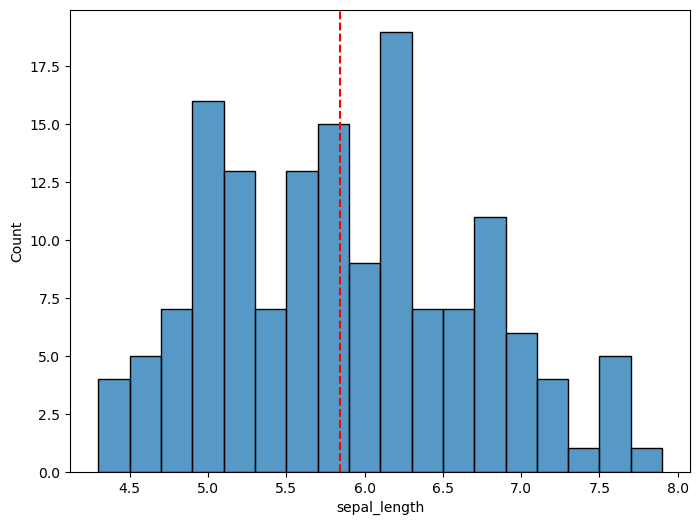

In [9]:
fig, ax = plt.subplots(figsize = (8,6))
sns.histplot(data = iris_sns, x = "sepal_length", binwidth = 0.2, ax = ax  )#
# mark the mean of sepal length
ax.axvline(x = iris_sns.sepal_length.mean(),color = 'r', ls = '--')



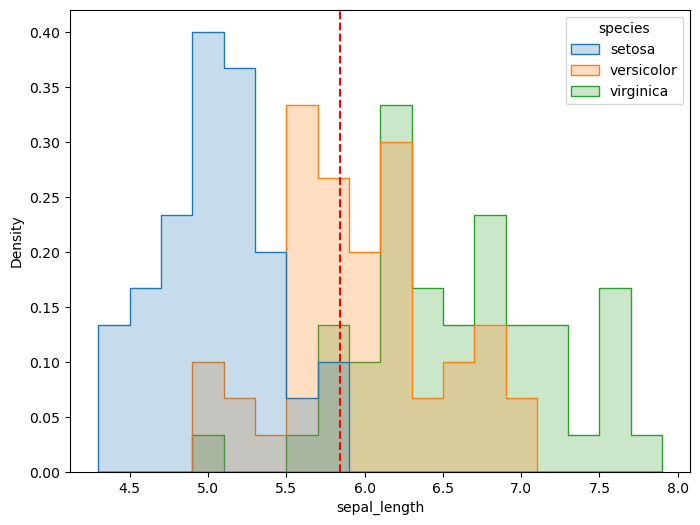

In [10]:
fig, ax = plt.subplots(figsize = (8,6))
sns.histplot(data = iris_sns, x = "sepal_length", 
             hue = 'species',binwidth = 0.2, ax = ax,
            element = "step", stat = 'density')
# mark the mean of sepal length
ax.axvline(x = iris_sns.sepal_length.mean(),color = 'r', ls = '--')

<Axes: xlabel='sepal_length', ylabel='Density'>

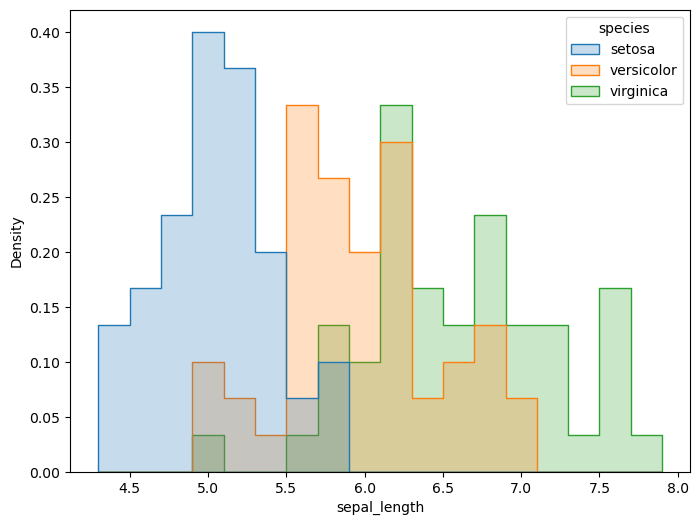

In [14]:
# 绘制花萼长度样本数据直方图，考虑鸢尾花分类
fig, ax = plt.subplots(figsize = (8,6))

sns.histplot(data=iris_sns, x="sepal_length", 
             hue = 'species', binwidth=0.2, ax = ax, 
             element="step", stat = 'density')
# 纵轴为概率密度


<Axes: xlabel='sepal_length', ylabel='species'>

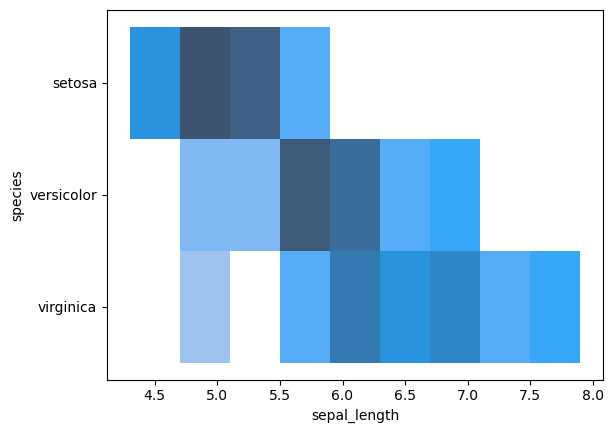

In [5]:
sns.histplot(iris_sns,x = "sepal_length",
           y = "species", legend = True)

<Axes: xlabel='species', ylabel='sepal_length'>

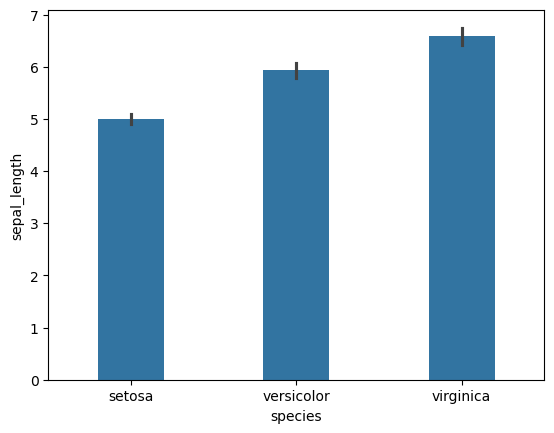

In [8]:
sns.barplot(data=iris_sns, x="species", y="sepal_length", width=0.4)

## gaussian kernel density estimation by seaborn

<Axes: xlabel='sepal_length', ylabel='Density'>

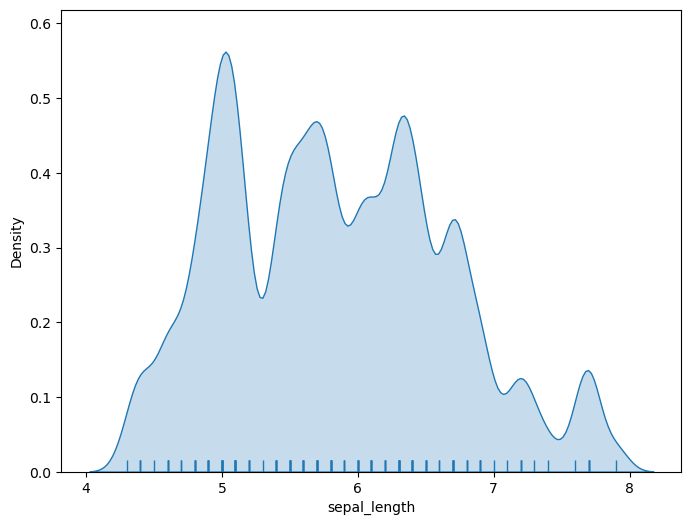

In [9]:
# 绘制花萼长度样本数据，高斯核密度估计
fig, ax = plt.subplots(figsize = (8,6))

sns.kdeplot(data=iris_sns, x="sepal_length", 
            bw_adjust=0.3, fill = True)
sns.rugplot(data=iris_sns, x="sepal_length")

<Axes: xlabel='sepal_length', ylabel='Density'>

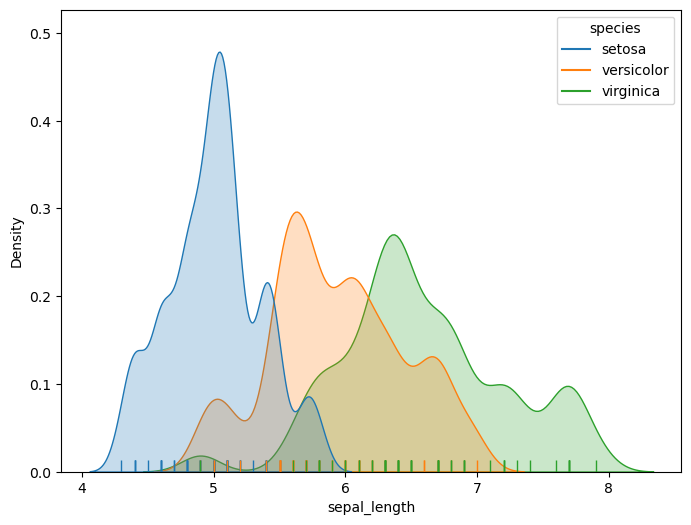

In [5]:
fig, ax = plt.subplots(figsize = (8,6))

sns.kdeplot(data=iris_sns, x="sepal_length", hue = 'species', 
            bw_adjust=0.5, fill = True)

sns.rugplot(data=iris_sns, x="sepal_length", hue = 'species')


此张图分别有三个品类
setosa
versicolor
virginica

曲线图： 由初始数据得出相关品类得概率分布图形
底部竖线： 二次观察得出 sepal_length 得数值
a:如数值全在分布曲线内，说明无异常值
b:如由数值不在分布曲线内，说明存在异常

1.分布不重叠， sepal_length 是区分品类得特征值

Gaussian Kernel Density Estimation
缩写：GKDE
常用简称：Kernel Density Estimation (KDE，默认核函数就是高斯核 Gaussian kernel)
 
 
 
工程用途（岩土工程方向）
 
1. 概率分布拟合
不需要提前假设数据服从正态分布。
用勘察、土工试验、监测得到的离散样本（黏聚力c、内摩擦角φ、渗透系数k），自动拟合出连续的概率密度曲线。
 
区别：正态分布是一条固定形状的钟形曲线；高斯核密度可以拟合任意形状分布，多峰、偏态。
 
2. 参数不确定性分析（可靠度）
生成参数的概率密度，用于蒙特卡洛抽样，计算边坡、地基失效概率、可靠指标β。
3. 二维联合概率密度
两个岩土参数(c‑φ)，二维GKDE画出等高线密度图，判断参数最可能落在哪个组合区间。
4. 监测数据异常识别
根据历史监测数据（沉降、孔隙水压）构建核密度，新测点密度值很低，则判定为异常，预警。
5. 随机场、空间插值预处理
对空间采样得到的地质参数做密度估计，作为构建随机有限元的输入。


高斯核密度估计(GKDE)是一种非参数概率密度估计方法，不需要预先假定样本服从某类分布，利用高斯核函数，由离散工程试验、勘察样本拟合得到连续概率密度函数，广泛用于岩土参数分布拟合、可靠度计算、风险评估。





1.确定数据分布形态
正态分布，对数正态分布，高斯核密度估计

2.确定数据分布形式之目的
a预先处理数据，发现是否有异常值

b确定分布形态，计算相关概率，运用贝叶斯反推岩土相关参数
：比如实测沉降，孔隙水压，反推岩土内摩擦角，粘聚力

c确定得出之结论是否满足数据支撑



3.3类机器学习实现方法
①A:密度估计型（KDE、GMM）——和你说的一致
 
- 训练：从正常样本拟合概率密度 p(x)
- 预测：输入新数据x，计算 p(x)
- 决策：设定阈值，如果p(x)<阈值 → 异常。
 
👉岩土工程例子：
用大量正常工况下沉降监测数据训练KDE；
某一天沉降值对应的密度极低，判定大概率异常，预警。
 
缺点：样本量大才靠谱；带宽敏感；外推不可信。
 
② B:分类模型（逻辑回归、随机森林）
 
不学完整分布，只学决策边界，直接输出类别。
 
不会输出完整概率密度，只输出“属于A类的概率”。
 
③C:贝叶斯模型
 
训练得到先验分布；拿到新观测数据，更新得到后验分布。
不是判断“是否在分布内”，而是更新参数的概率。


<Axes: xlabel='sepal_length', ylabel='Density'>

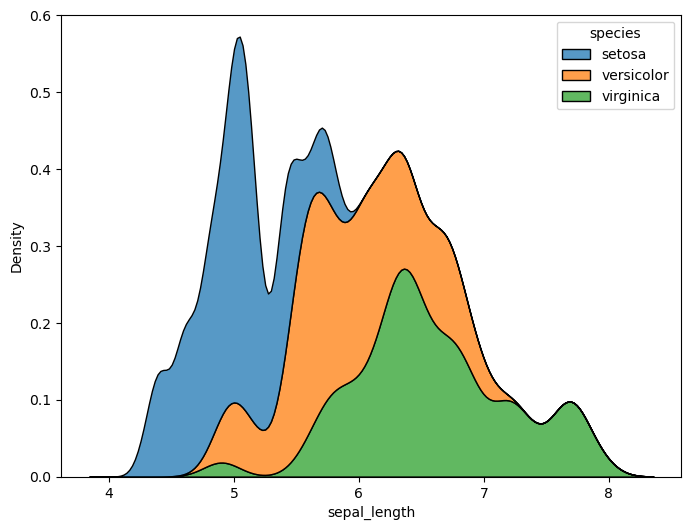

In [7]:
fig, ax = plt.subplots(figsize = (8,6))
sns.kdeplot(data = iris_sns, x= "sepal_length", hue = "species",
           multiple = "stack", bw_adjust = 0.5)


<Axes: xlabel='sepal_length', ylabel='Density'>

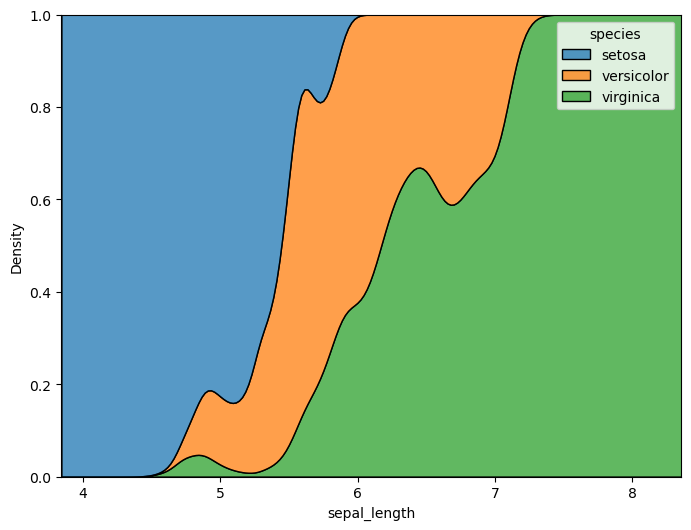

In [11]:
fig, ax = plt.subplots(figsize = (8,6))
sns.kdeplot(data=iris_sns, x="sepal_length", 
            hue="species", bw_adjust=0.5, multiple = 'fill')

## the point picture with seaborn

<Axes: xlabel='sepal_length', ylabel='species'>

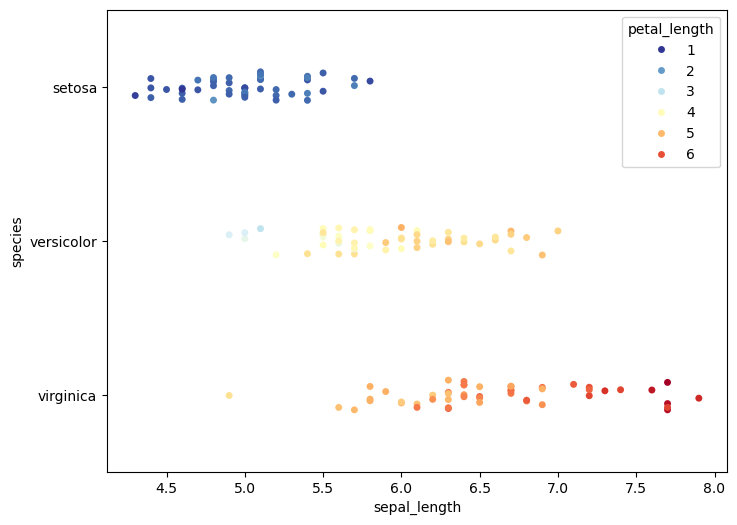

In [7]:
fig,ax = plt.subplots(figsize = (8,6))

sns.stripplot(data = iris_sns, x = "sepal_length", y = "species", 
             hue = "petal_length", palette = "RdYlBu_r", ax = ax)


<Axes: xlabel='sepal_length', ylabel='species'>

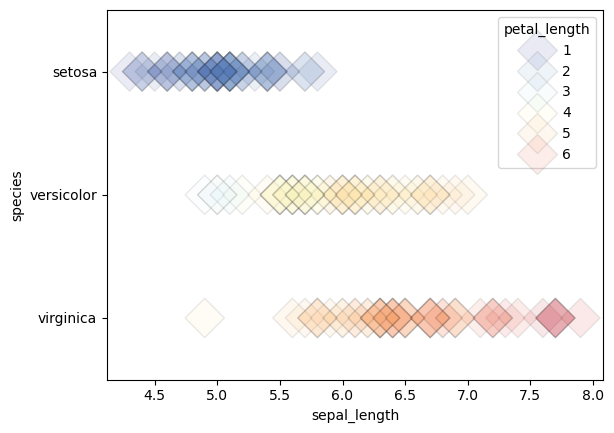

In [8]:
sns.stripplot(
    data=iris_sns, x="sepal_length", y="species", hue="petal_length",
    jitter=False, s=20, marker="D", linewidth=1, alpha=.1, palette="RdYlBu_r",
)

<Axes: xlabel='sepal_length', ylabel='species'>

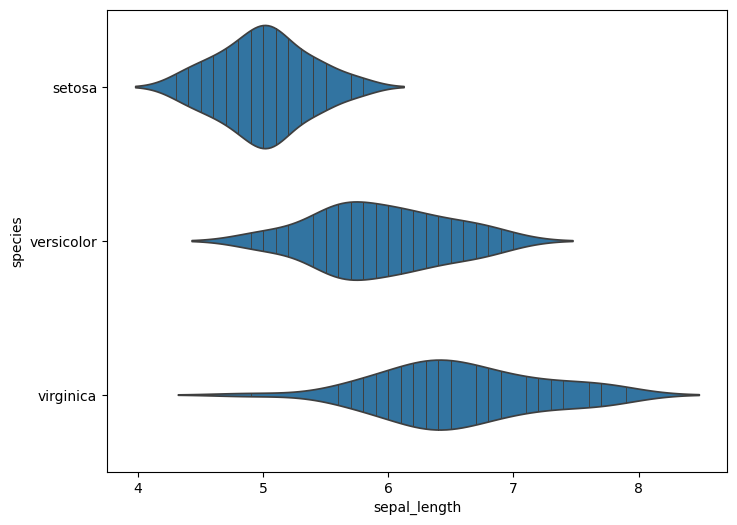

In [16]:
fig, ax = plt.subplots(figsize = (8,6))

sns.violinplot(data=iris_sns, x="sepal_length", y = "species", 
                 inner = 'stick')

<Axes: xlabel='sepal_length'>

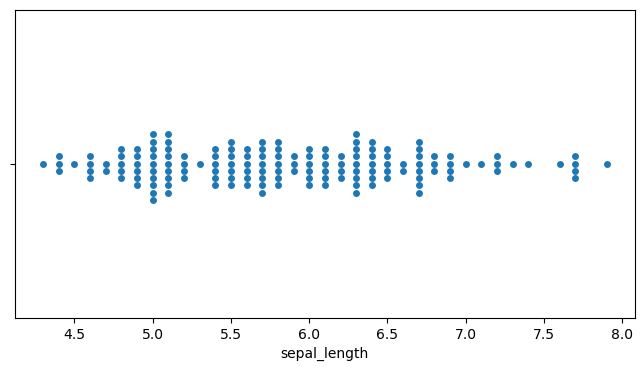

In [17]:
fig, ax = plt.subplots(figsize = (8,4))

sns.swarmplot(data=iris_sns, x="sepal_length", ax = ax)

In [1]:
fig, ax = plt.subplots(figsize = (8,4))

NameError: name 'plt' is not defined

##  import the local data seaborn_data

In [2]:

import os
import seaborn as sns
  
os.environ["SEABORN_DATA"] = "/home/lee/ogs-py310/iris_data/seaborn-data-master/seaborn-data-master"

iris_sns = sns.load_dataset("iris")


In [5]:
 
 iris_sns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [18]:
 
pwd


'/home/lee/ogs-py310/iris_data'

In [19]:
ls

seaborn-data-master/  seaborn-data-master.zip*


In [1]:
pwd


'/home/lee/ogs-py310'

<Axes: xlabel='sepal_length', ylabel='species'>

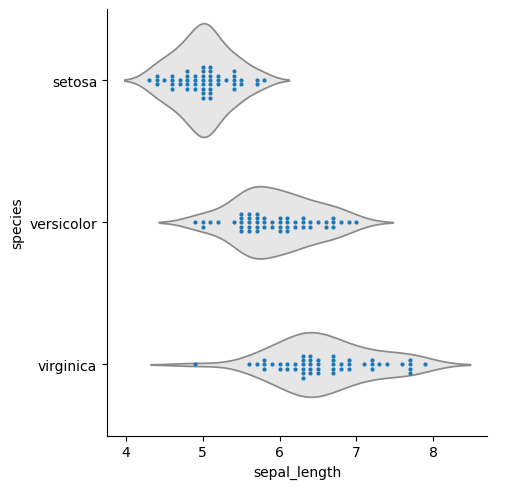

In [9]:

sns.catplot(data=iris_sns, x="sepal_length", y="species", 
            kind="violin", color=".9", inner=None)

sns.swarmplot(data=iris_sns, x="sepal_length", y = 'species', 
              size = 3)


<Axes: xlabel='sepal_length', ylabel='species'>

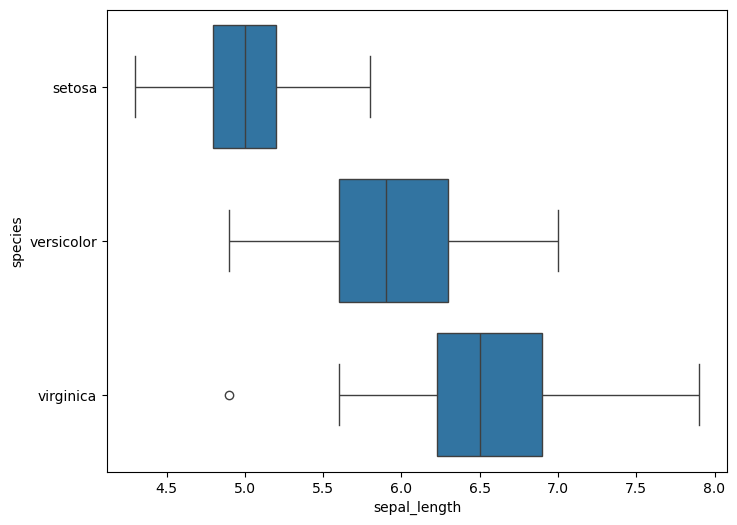

In [14]:
fig, ax = plt.subplots(figsize = (8,6))
sns.boxplot(data=iris_sns, x="sepal_length",y = "species", ax = ax)




/tmp/ipykernel_1817/135185895.py:1: FutureWarning: 

The `scale` parameter has been renamed to `width_method` and will be removed in v0.15. Pass `width_method='linear' for the same effect.
  sns.boxenplot(data=iris_sns, x="sepal_width",y = "species", scale = "linear")


<Axes: xlabel='sepal_width', ylabel='species'>

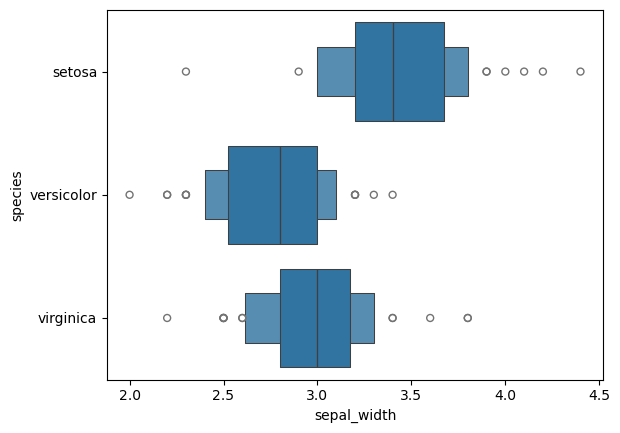

In [16]:
sns.boxenplot(data=iris_sns, x="sepal_width",y = "species", scale = "linear")


In [17]:
iris_sns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


<Axes: xlabel='sepal_length', ylabel='petal_length'>

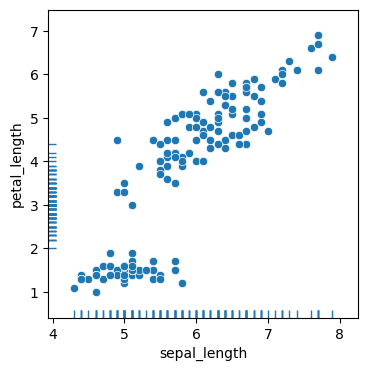

In [18]:
fig, ax = plt.subplots(figsize = (4,4))

sns.scatterplot(data=iris_sns, x="sepal_length", y="petal_length")
sns.rugplot(data=iris_sns, x="sepal_length", y="sepal_width")





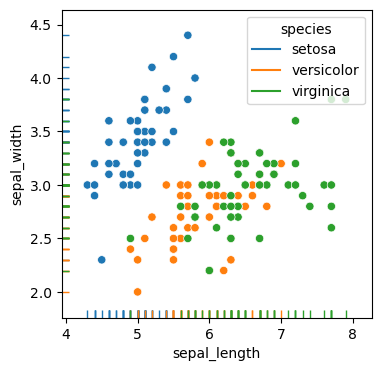

In [19]:

fig, ax = plt.subplots(figsize = (4,4))

sns.scatterplot(data=iris_sns, x="sepal_length", y="sepal_width", 
                hue = 'species')
sns.rugplot(data=iris_sns, x="sepal_length", y="sepal_width", 
            hue = 'species')

fig.savefig('Figures\二元，scatterplot + rugplot + hue.svg', format='svg')


##  the two demenstration  density with seaborn

In [3]:
import os
import seaborn as sns
import pandas as pd
os.environ["SEABORN_DATA"] = "/home/lee/ogs-py310/iris_data/seaborn-data-master/seaborn-data-master"

iris_sns = sns.load_dataset("iris")


In [8]:
iris_sns

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


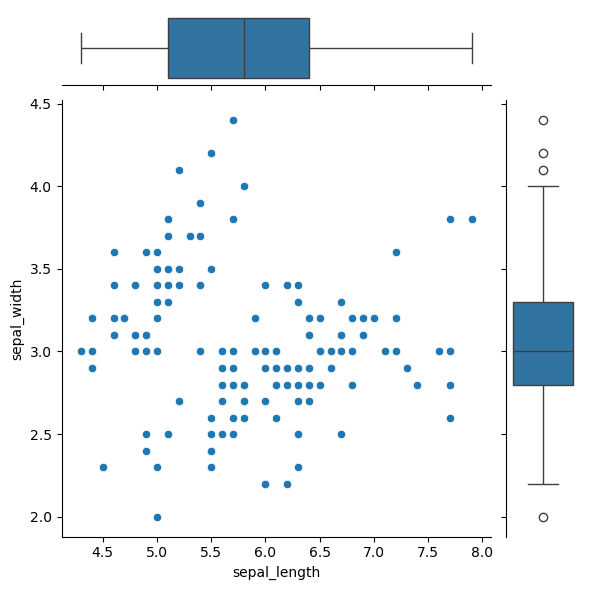

In [10]:
g = sns.JointGrid(data = iris_sns, x = "sepal_length", y = "sepal_width")

g.plot_joint(sns.scatterplot)

g.plot_marginals(sns.boxplot)


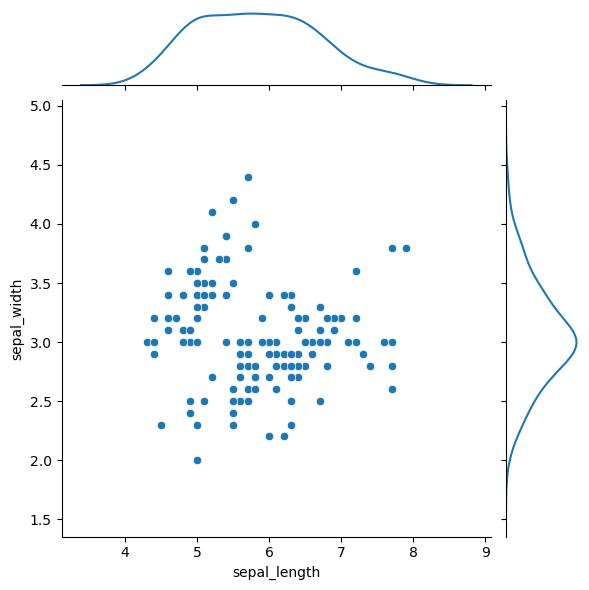

In [12]:
g = sns.JointGrid(data = iris_sns, x = "sepal_length", y = "sepal_width")

g.plot_joint(sns.scatterplot)

g.plot_marginals(sns.kdeplot)

 ## the probability heatmap

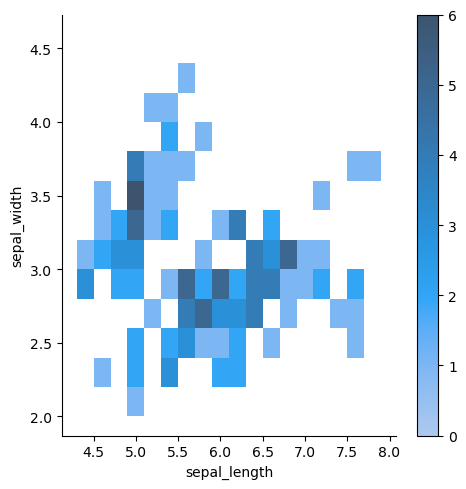

In [14]:
sns.displot(data=iris_sns, x="sepal_length", y="sepal_width",
           binwidth = (0.2, 0.2), cbar = True)

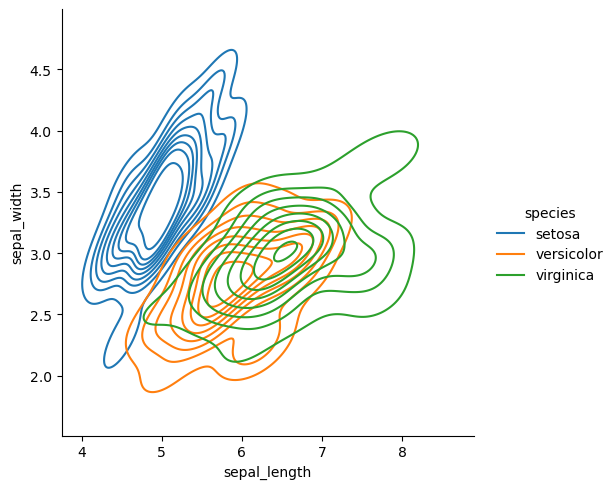

In [16]:
sns.displot(data=iris_sns, x="sepal_length", 
            y="sepal_width", kind = "kde", hue = 'species')

## visualizing regrassion models

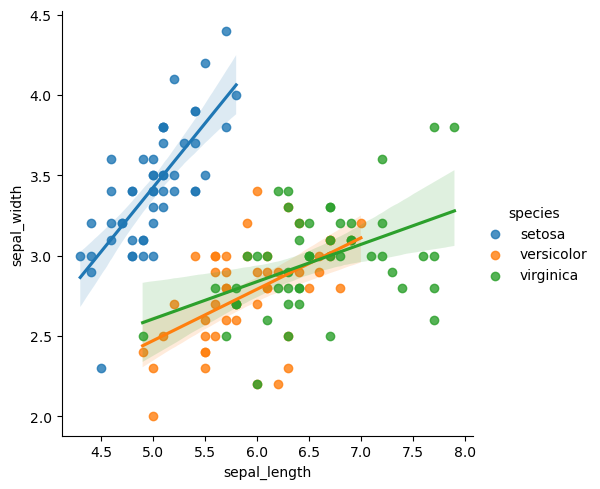

In [19]:
sns.lmplot(data = iris_sns, x = "sepal_length", y = "sepal_width"
          , hue = 'species')

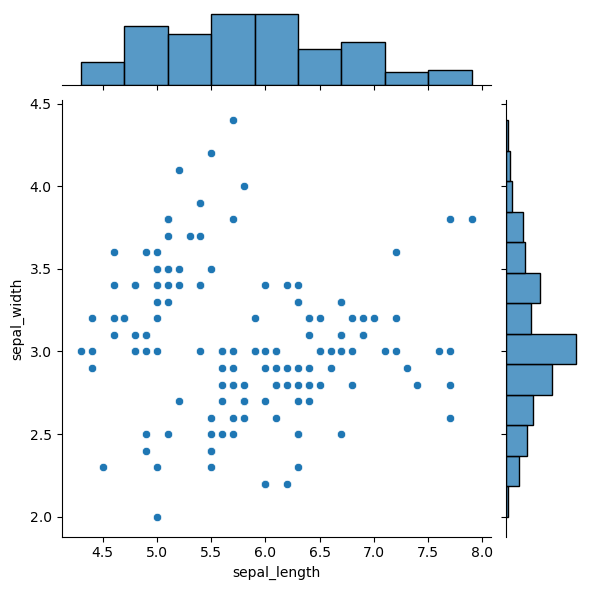

In [21]:
sns.jointplot(data=iris_sns, x="sepal_length",  y = "sepal_width")



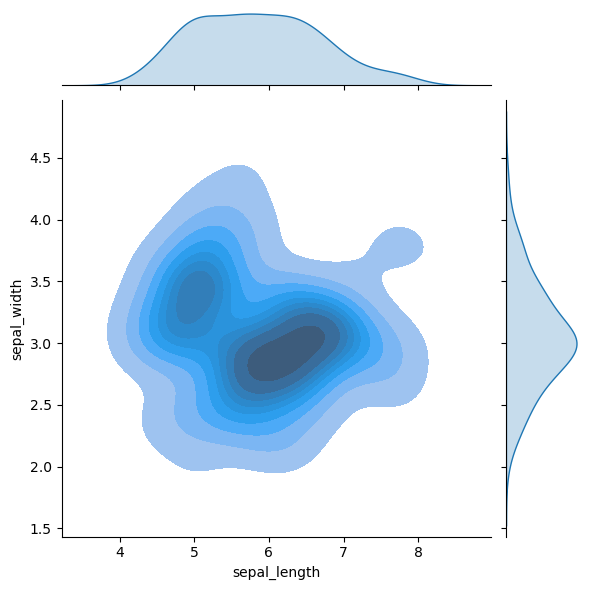

In [25]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width"
             ,kind = 'kde', fill = True)



## kde with points


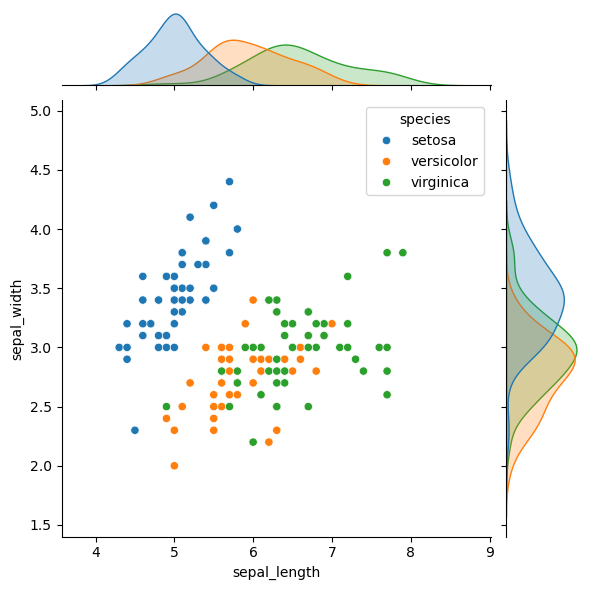

In [3]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width", hue = 'species' )

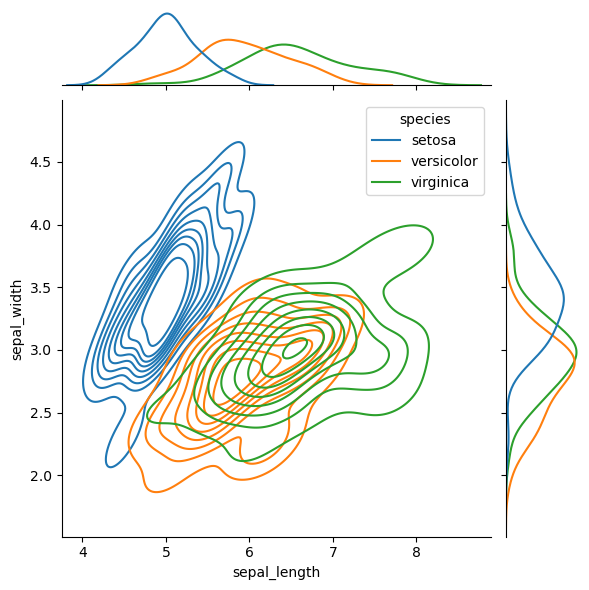

In [4]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width",
             hue = 'species', kind = "kde")

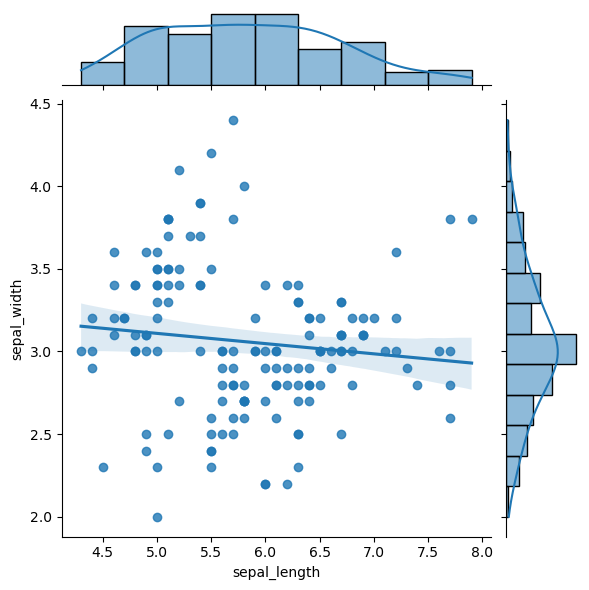

In [5]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width", kind = "reg")

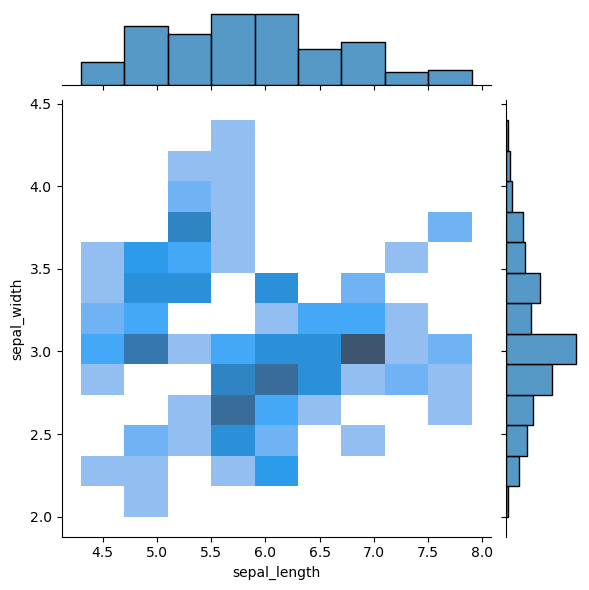

In [6]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width", kind = "hist")

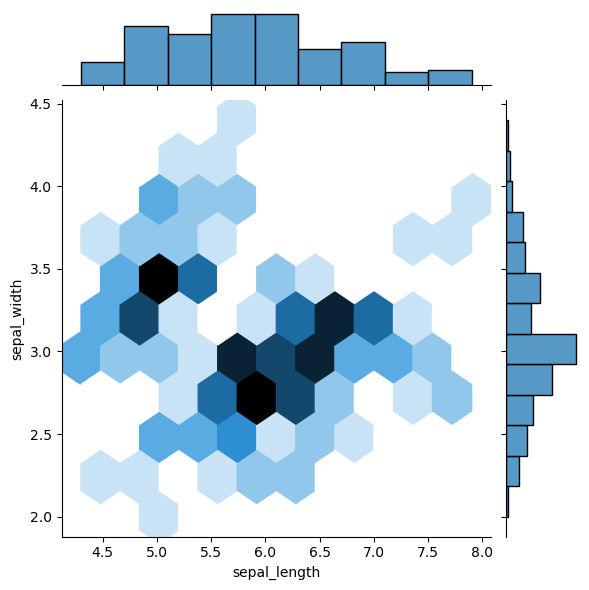

In [7]:
sns.jointplot(data = iris_sns, x = "sepal_length", y = "sepal_width", kind = "hex")

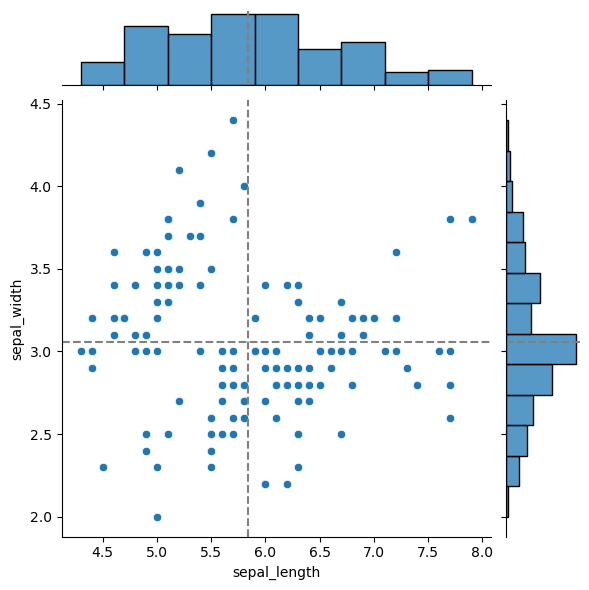

In [10]:
g = sns.JointGrid(data = iris_sns, x = "sepal_length", y = "sepal_width")
g.plot(sns.scatterplot, sns.histplot)
g.refline(x = iris_sns['sepal_length'].mean(), y = iris_sns['sepal_width'].mean() )



In [13]:
iris_melt = pd.melt(iris_sns, "species", var_name = "measurement")

In [14]:
iris_melt

,species,measurement,value
0,setosa,sepal_length,5.1
1,setosa,sepal_length,4.9
2,setosa,sepal_length,4.7
3,setosa,sepal_length,4.6
4,setosa,sepal_length,5.0
...,...,...,...
595,virginica,petal_width,2.3
596,virginica,petal_width,1.9
597,virginica,petal_width,2.0
598,virginica,petal_width,2.3


##  more than one variable / multivariable


In [1]:
import matplotlib.pyplot as plt

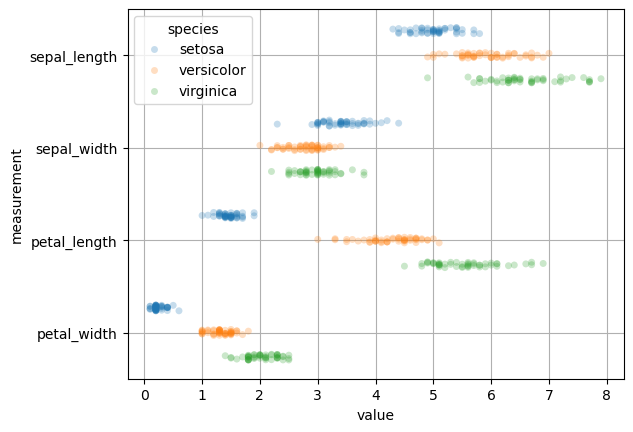

In [4]:
iris_melt = pd.melt(iris_sns, "species", var_name = "measurement")

sns.stripplot(
    data = iris_melt, x = "value", y = "measurement", hue = "species",
    dodge = True, alpha = .25, legend = True)

plt.grid()



<Axes: xlabel='value', ylabel='measurement'>

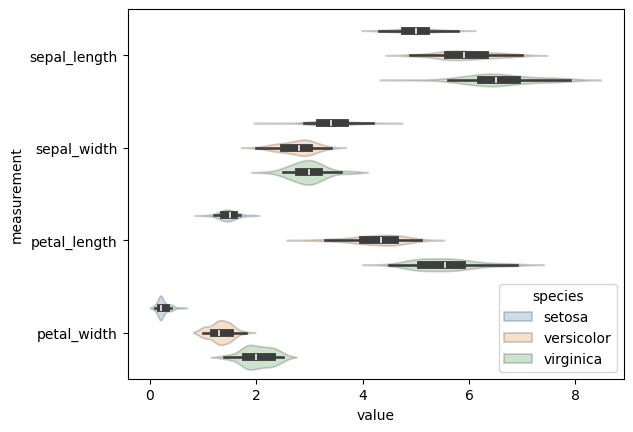

In [6]:
iris_melt = pd.melt(iris_sns, "species", var_name = "measurement")
sns.violinplot(
    data = iris_melt,x = "value", y = "measurement", hue = "species", 
    dodge = True, alpha = .25, zorder = 1, legend = True)

<Axes: >

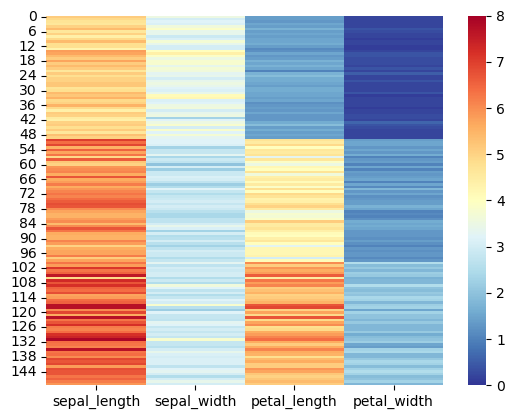

In [10]:
sns.heatmap(iris_sns.iloc[:,:-1], cmap = 'RdYlBu_r', vmin = 0, vmax = 8)

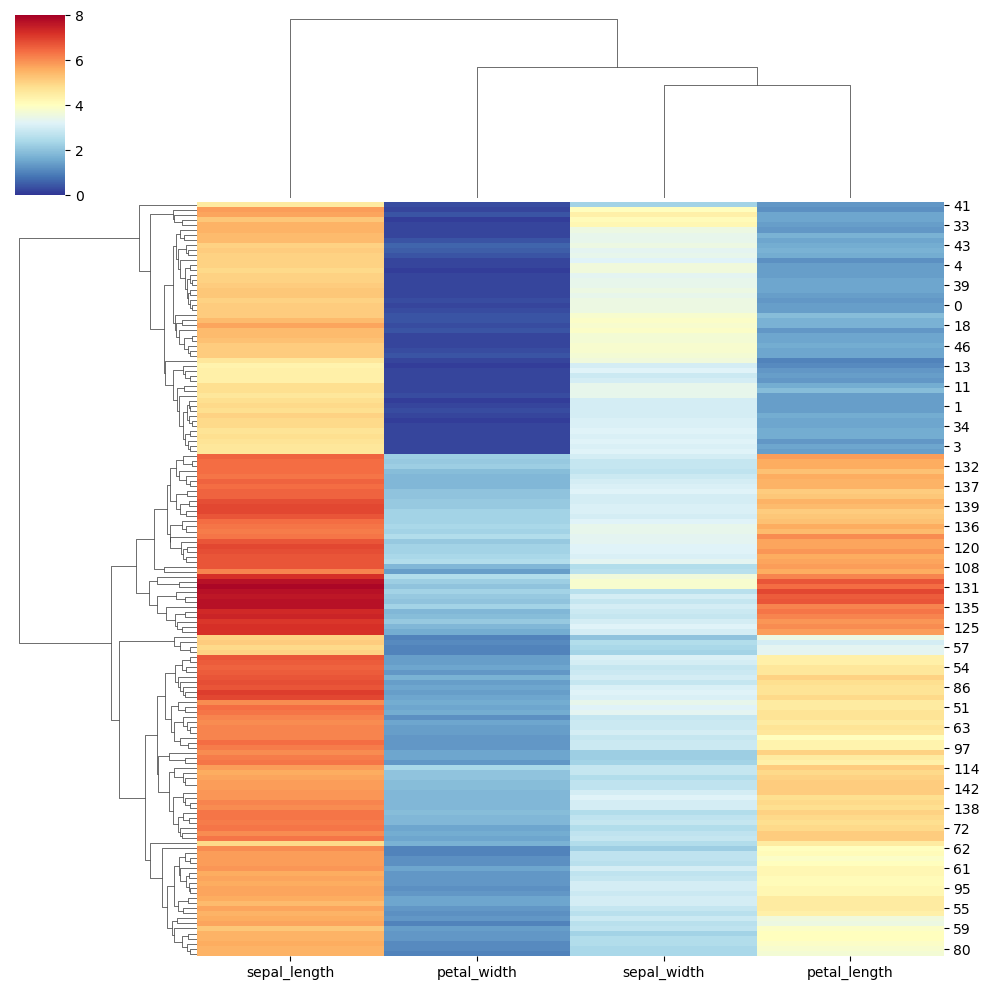

In [12]:
sns.clustermap(iris_sns.iloc[:,:-1], cmap = 'RdYlBu_r', 
              vmin = 0 , vmax = 8)

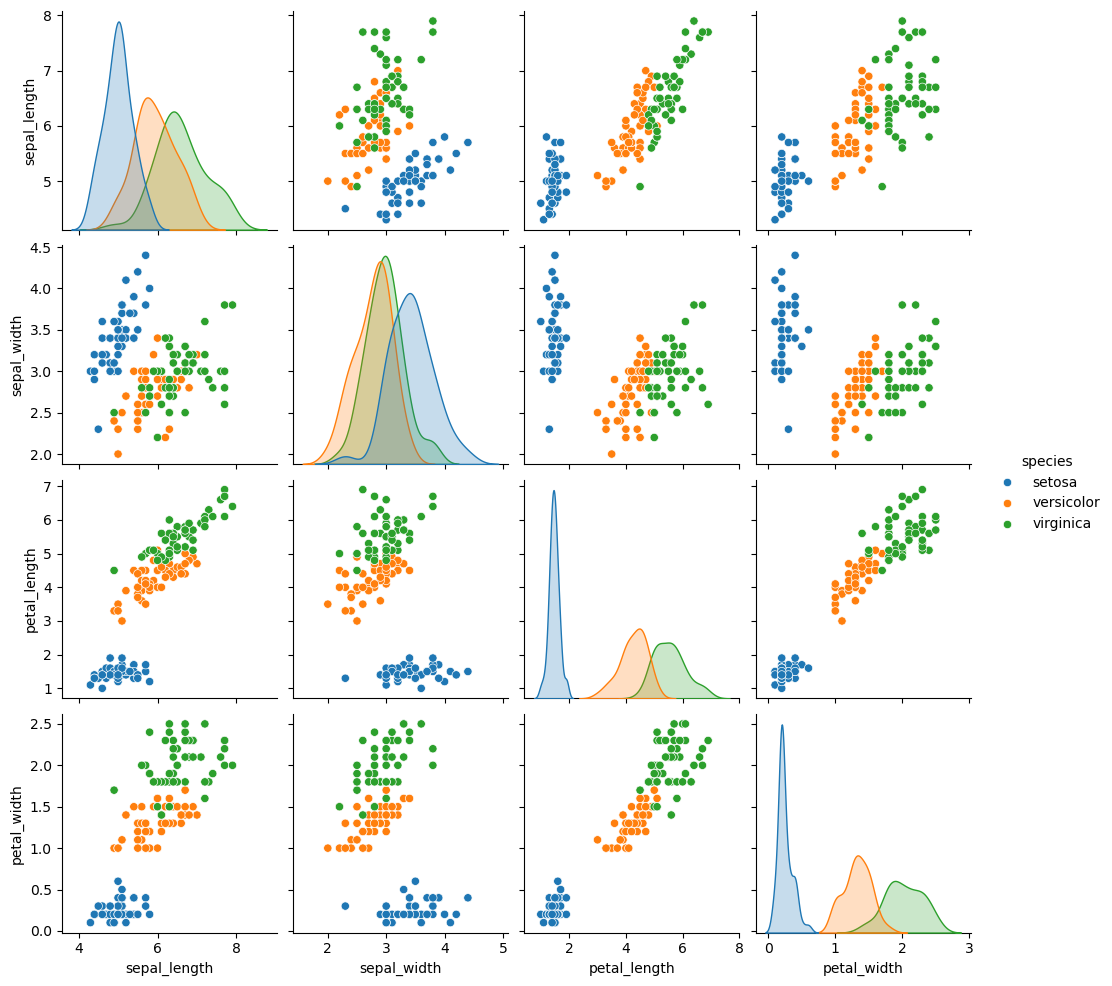

In [14]:
sns.pairplot(iris_sns,hue = 'species')

pairplot（配对散点矩阵图）工程目的
 
这张图是多变量两两配对分析图：对角线是单变量直方图（看单个参数分布），其余子图是两个变量之间的散点图（看变量之间相关关系）。
 
工程用途
 
1. 快速筛查变量相关性
一眼判断哪两个参数存在正相关、负相关、几乎无关。
 
岩土工程举例：土层黏聚力、内摩擦角、含水率、密度，两两查看是否存在明显相关趋势，为后续可靠度分析、代理模型筛选变量。
 
2. 识别异常值、离群样本
散点上远离主集群的点，大概率是试验异常数据，用来排查试验失误、录入错误。
3. 判断变量分布形态
对角线直方图，观察参数是否近似正态分布，为后续概率可靠度计算选择合适的概率分布函数提供依据。
4. 变量筛选，降维
如果两个变量高度线性相关，可以只保留一个，避免多重共线性，减少机器学习模型冗余输入，降低计算量。
5. 初步判断是否适合线性拟合
散点如果呈一条斜向带状，可以考虑线性回归；如果是非线性曲线，则需要采用非线性拟合（高斯核密度、贝叶斯等）
普通非线性拟合：
确定最大值
贝叶斯非线性拟合：
确定参数值可能落在的区间，即置信区间

/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'level'
  cset = contour_func(
/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'level'
  cset = contour_func(
/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'level'
  cset = contour_func(
/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'level'
  cset = contour_func(
/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'level'
  cset = contour_func(
/home/lee/miniconda3/envs/ogs-py310/lib/python3.10/site-packages/

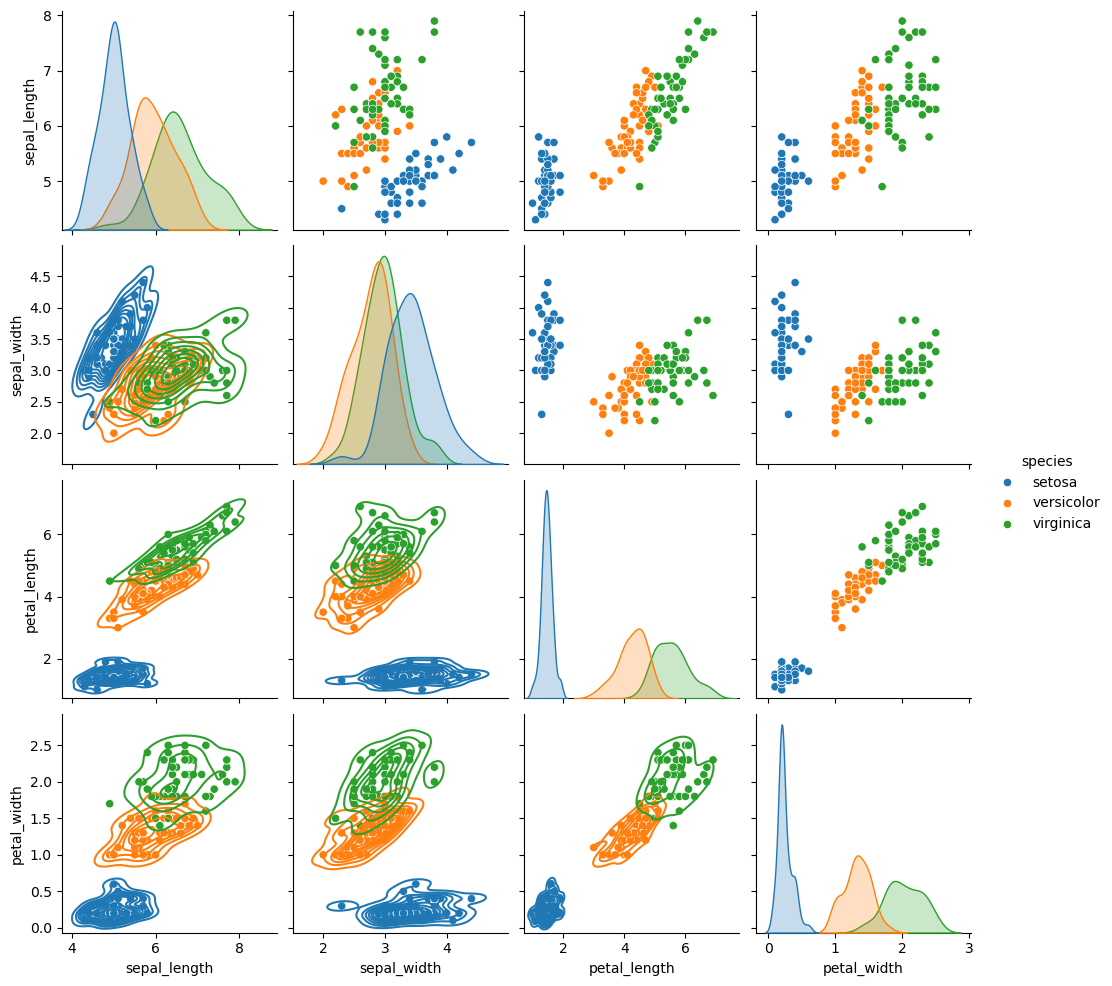

In [15]:
g = sns.pairplot(iris_sns,hue = 'species')
g.map_lower(sns.kdeplot, level = 8, color = ".2")

 对角线：分组核密度KDE曲线，展示每个变量，三类样本各自的概率分布
非对角线：二维等高线密度图，展示两个变量联合概率密度，等高线越密，该参数组合出现概率越高
三种颜色 = 3个类别（三类鸢尾花）
 
图中可以读出的信息
 
1. 单变量分布（对角线）
每个特征单独看，三类样本的峰值位置、分布宽度不一样。
比如 petal_length （花瓣长度）：蓝色setosa峰值明显靠左，可以仅凭花瓣长度就很大概率区分它；橙色、绿色有部分重叠，不容易一刀切分开。
2. 二维联合概率（等高线）
等高线围成的区域，就是参数组合高概率区域。
等高线形状可以判断相关性：
 
- 斜拉长椭圆：两个参数具有相关性
- 接近圆形：两个参数相关性弱
 
3. 类别重叠区
橙色versicolor与绿色virginica多个特征存在重叠区域。
👉 意味着：只用单个指标不能100%区分两类，需要多变量联合判断。
 
 
 
迁移到岩土工程的工程目的
 
把三类鸢尾花，替换成三种工况、三类地层、三种破坏模式
 
1. 聚类识别
等高线聚集区代表该类工况下，岩土参数最常落在的组合范围；重叠区代表参数组合容易发生模式误判。
2. 获取二维概率密度（二维概率热图）
等高线就是二维KDE，得到一组参数同时出现的概率，可用于蒙特卡洛抽样、可靠度计算。
3. 特征重要性筛选
像花瓣长度一样，能够把各类明显分开的参数，是区分破坏模式的强特征；大量重叠的是弱特征，可以酌情剔除，减少模型输入维度。
4. 划定安全/危险参数域
等高线高密度区=工程上高频出现的参数组合；低密度外围=少见、偏危险的参数组合。

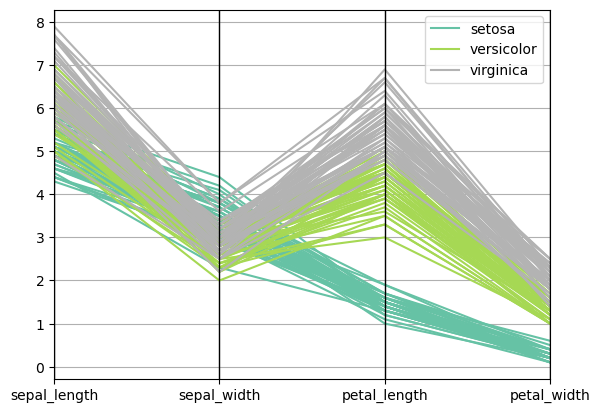

In [19]:
from pandas.plotting import parallel_coordinates
parallel_coordinates(iris_sns, 'species', colormap = plt.get_cmap("Set2"))

plt.show()


<Axes: >

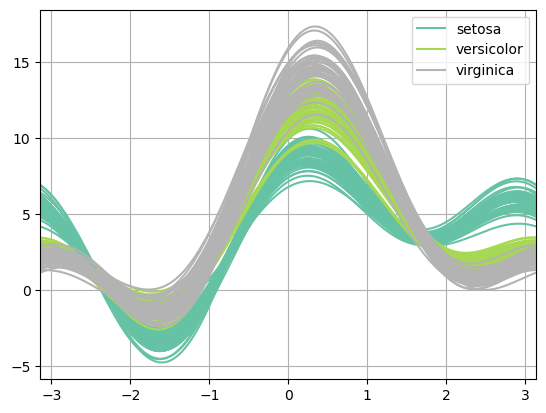

In [20]:
from pandas.plotting import andrews_curves

andrews_curves(iris_sns, 'species', colormap = plt.get_cmap("Set2"))

<Axes: >

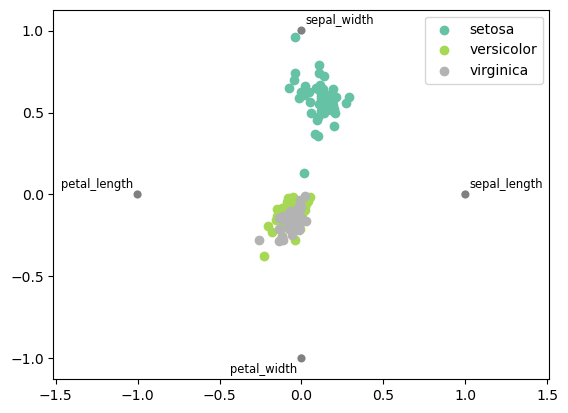

In [21]:
from pandas.plotting import radviz
radviz(iris_sns, 'species', colormap = plt.get_cmap("Set2"))

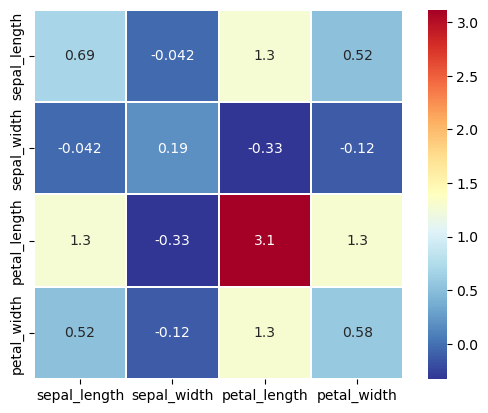

In [25]:
SIGMA = iris_sns.iloc[:,:-1].cov()
fig,axs = plt.subplots()
h = sns.heatmap(SIGMA, cmap = 'RdYlBu_r', linewidth = .05, annot = True)
h.set_aspect("equal")





Text(0.5, 1.0, 'virginica')

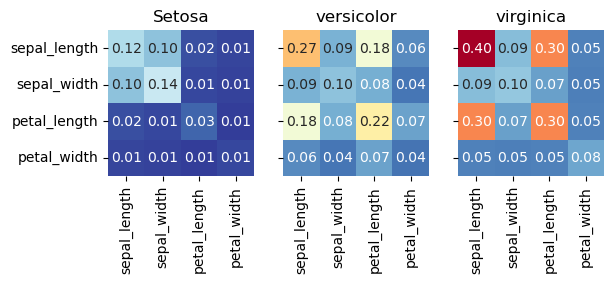

In [4]:
f,(ax1, ax2, ax3) = plt.subplots(1,3,sharey = True)

features = list(iris_sns.columns)[:-1]

g1 = sns.heatmap(iris_sns.loc[iris_sns.species == 'setosa',features].cov(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax1, square = True,
                vmax = 0.4, vmin = 0)

ax1.set_title('Setosa')

g2 = sns.heatmap(iris_sns.loc[iris_sns.species == 'versicolor',features].cov(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax2, square = True,
                vmax = 0.4, vmin = 0)

ax2.set_title('versicolor')

g3 = sns.heatmap(iris_sns.loc[iris_sns.species == 'virginica',features].cov(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax3, square = True,
                vmax = 0.4, vmin = 0)

ax3.set_title('virginica')





Text(0.5, 1.0, 'virginica')

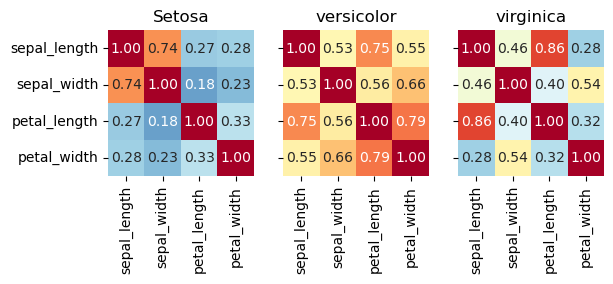

In [6]:
 f,(ax1, ax2, ax3) = plt.subplots(1,3,sharey = True)

features = list(iris_sns.columns)[:-1]

g1 = sns.heatmap(iris_sns.loc[iris_sns.species == 'setosa',features].corr(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax1, square = True,
                vmax = 1, vmin = 0)

ax1.set_title('Setosa')

g2 = sns.heatmap(iris_sns.loc[iris_sns.species == 'versicolor',features].corr(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax2, square = True,
                vmax = 1, vmin = 0)

ax2.set_title('versicolor')

g3 = sns.heatmap(iris_sns.loc[iris_sns.species == 'virginica',features].corr(),
                cmap = "RdYlBu_r",fmt = '.2f',
                annot = True, cbar = False, ax = ax3, square = True,
                vmax = 1, vmin = 0)

ax3.set_title('virginica')







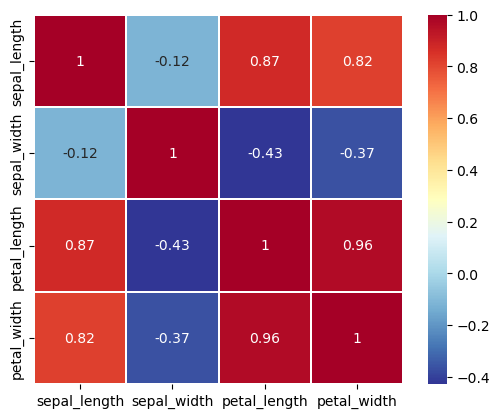

In [7]:
RHO = iris_sns.iloc[:, :-1].corr()
fig,axs = plt.subplots()
h = sns.heatmap(RHO,cmap='RdYlBu_r', linewidths=.05, annot = True)
h.set_aspect("equal")

In [15]:
import matplotlib.pyplot as plt 
import pandas as pd  
import seaborn as sns 

import numpy as np

import os

import seaborn as sns
os.environ["SEABORN_DATA"] = "/home/lee/ogs-py310/iris_data/seaborn-data-master/seaborn-data-master"
iris_sns = sns.load_dataset("iris")




In [2]:
iris_sns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


##  相关性矩阵与协方差矩阵



协方差矩阵受量纲影响大
相关性矩阵对协方差矩阵归一化处理



In [7]:
iris_sns.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [8]:
iris_sns.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [11]:
iris_sns.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


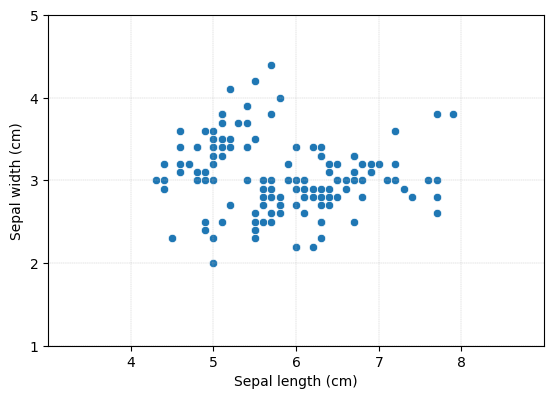

In [20]:
fig, ax = plt.subplots()

ax = sns.scatterplot(data=iris_sns, 
                     x="sepal_length", 
                     y="sepal_width")

ax.set_xlabel('Sepal length (cm)')
ax.set_ylabel('Sepal width (cm)')

ax.set_xticks(np.arange(4, 8 + 1, step=1))
ax.set_yticks(np.arange(1, 5 + 1, step=1))

ax.axis('scaled')

ax.grid(linestyle='--', linewidth=0.25, color=[0.7,0.7,0.7])

ax.set_xbound(lower = 3, upper = 9)
ax.set_ybound(lower = 1, upper = 5)



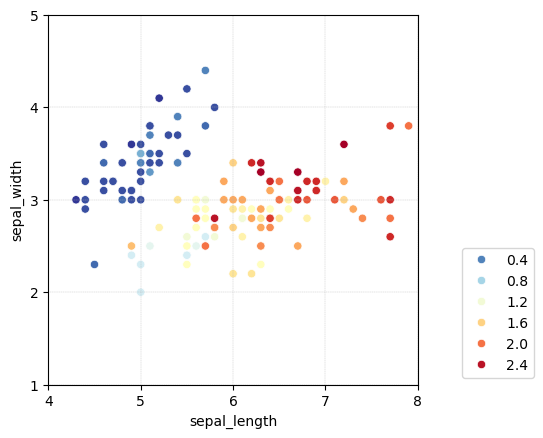

In [35]:
fig, ax = plt.subplots()

ax = sns.scatterplot(data=iris_sns, x="sepal_length", 
                     y="sepal_width", hue = "petal_width",palette = 'RdYlBu_r')
ax.set_xticks(np.arange(4, 8 + 1, step=1))
ax.set_yticks(np.arange(1, 5 + 1, step=1))
 
ax.axis('scaled')
ax.grid(linestyle='--', linewidth=0.25, color=[0.7,0.7,0.7])

ax.set_xbound(lower = 4, upper = 8)
ax.set_ybound(lower = 1, upper = 5)

ax.legend(loc = 'lower left', bbox_to_anchor = (1.1, 0), ncol = 1)

## 多特征图谱绘制

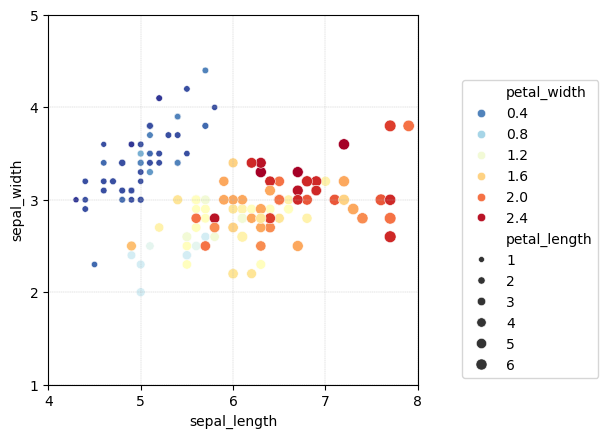

In [36]:
fig, ax = plt.subplots()

ax = sns.scatterplot(data=iris_sns, x="sepal_length", 
                     y="sepal_width", hue = "petal_width",
                     size = "petal_length", palette = 'RdYlBu_r')
ax.set_xticks(np.arange(4, 8 + 1, step=1))
ax.set_yticks(np.arange(1, 5 + 1, step=1))
 
ax.axis('scaled')
ax.grid(linestyle='--', linewidth=0.25, color=[0.7,0.7,0.7])

ax.set_xbound(lower = 4, upper = 8)
ax.set_ybound(lower = 1, upper = 5)

ax.legend(loc = 'lower left', bbox_to_anchor = (1.1, 0), ncol = 1)